$ \huge{Deep \ Reinforcement \ Learning: \ Playing \ Ms. \ Pac \text{-} Man} $

**Author:** Alberto Valdés

In this project we will use the **"Dueling DQN"** network architecture (combined with the **Double DQN** target) to learn the best action policy for the Atari game **"Ms. Pac-Man"**.

The agent only sees the raw pixels of the screen and the score, exactly like a human player would. Its goal is to eat all the pellets of the maze while avoiding (or hunting, after a power pellet) the four ghosts.

$ \huge{Part \ 1: Implementation} $

## **Activity 1:**

The reason we use the **last 4 frames** of the game as the state is that a single image does not tell the network **where things are moving**. With 4 stacked frames the network can infer the direction and speed of Pac-Man and of every ghost, which is essential to decide whether to keep going down a corridor or turn back before a ghost catches us.

Now we will do all the preprocessing of the game states:

1. **Frame skip = 4:** the agent picks an action every 4 frames (the action is repeated in between).
2. **Grayscale:** color is not needed to tell walls, pellets and ghosts apart.
3. **Resize to 84 × 84:** smaller input, much cheaper convolutions.
4. **Frame stack = 4:** final state of shape $(4, 84, 84)$.

# Ms. Pac-Man setup

### Install libraries

In [1]:
# ale-py >= 0.9 already ships the Atari ROMs, so there is no need to download them manually
!pip install -q "gymnasium[atari]>=1.0" "ale-py>=0.9" opencv-python-headless

# > -q omits most of the command output

In [2]:
# Mount Google Drive (if we are on Colab) to save checkpoints between sessions
try:
    from google.colab import drive
    drive.mount('/content/drive')
    my_path = 'drive/MyDrive/DeepLearningUC/PacMan/Checkpoints'
except ImportError:
    my_path = './PacMan/Checkpoints'

print('Checkpoints folder:', my_path)

Mounted at /content/drive
Checkpoints folder: drive/MyDrive/DeepLearningUC/PacMan/Checkpoints


## Gym environment

In [3]:
import gymnasium as gym
import ale_py
import numpy as np
import matplotlib.pyplot as plt
import random
from gymnasium.wrappers import AtariPreprocessing, FrameStackObservation

gym.register_envs(ale_py)

game = 'ALE/MsPacman-v5'

def make_env(render_mode=None):
    # frameskip=1 and repeat_action_probability=0 because AtariPreprocessing does the frame skip
    env = gym.make(game, frameskip=1, repeat_action_probability=0.0, render_mode=render_mode)
    env = AtariPreprocessing(env,
                             noop_max=30,          # random number of NOOPs at the start of each episode
                             frame_skip=4,         # repeat each action 4 frames
                             screen_size=84,       # 84 x 84 images
                             grayscale_obs=True,
                             scale_obs=False)      # keep uint8 (0-255) to save memory
    env = FrameStackObservation(env, stack_size=4) # state of shape (4, 84, 84)
    return env

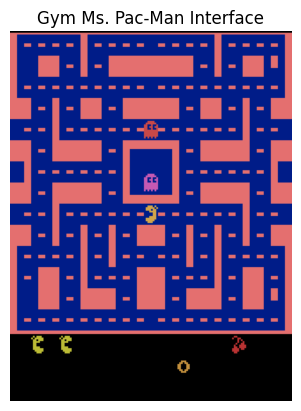

Original shape: (210, 160, 3)
Actions: ['NOOP', 'UP', 'RIGHT', 'LEFT', 'DOWN', 'UPRIGHT', 'UPLEFT', 'DOWNRIGHT', 'DOWNLEFT']


In [4]:
# For reproducibility
seed = 7
random.seed(seed)
np.random.seed(seed)

# Original game screen
raw_env = gym.make(game)
raw_obs, _ = raw_env.reset(seed=seed)

plt.imshow(raw_obs)
plt.title('Gym Ms. Pac-Man Interface')
plt.axis('off')
plt.show()

print('Original shape:', raw_obs.shape)
print('Actions:', raw_env.unwrapped.get_action_meanings())
raw_env.close()

Preprocessed state shape: (4, 84, 84)


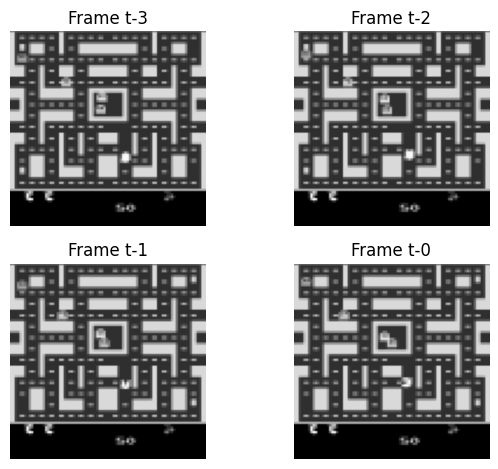

In [5]:
env = make_env()
obs, info = env.reset(seed=seed)

for _ in range(100):
    action = random.randint(0, env.action_space.n - 1)
    obs, reward, terminated, truncated, info = env.step(action)

print('Preprocessed state shape:', np.array(obs).shape)

plt.figure()
for i in range(4):
    plt.subplot(2, 2, i + 1)
    plt.imshow(np.array(obs)[i, :, :], cmap='gray')
    plt.title(f'Frame t-{3 - i}')
    plt.axis('off')
plt.tight_layout()
plt.show()

# Replay buffer

Each state is a `uint8` array of shape $(4, 84, 84)$, that is **28,224 bytes**. If we stored `state` **and** `next_state` for every transition, a buffer of 150,000 transitions would need ~8.5 GB of RAM, which does not fit in a standard Colab session.

To avoid this, the buffer stores each state **only once** in a circular `numpy` array: the `next_state` of transition $i$ is simply the `state` stored in position $i+1$. When the episode ends (`done = True`) the next state is not needed, because the target is just the reward. This cuts the memory in half (~4.2 GB).

In [6]:
class ReplayMemory(object):

    def __init__(self, capacity, state_shape=(4, 84, 84)):
        self.capacity = capacity
        self.states  = np.zeros((capacity, *state_shape), dtype=np.uint8)
        self.actions = np.zeros(capacity, dtype=np.int64)
        self.rewards = np.zeros(capacity, dtype=np.float32)
        self.dones   = np.zeros(capacity, dtype=np.bool_)
        self.pos  = 0   # next position to write
        self.size = 0   # number of stored transitions

    def push(self, state, action, reward, done):
        self.states[self.pos]  = state
        self.actions[self.pos] = action
        self.rewards[self.pos] = reward
        self.dones[self.pos]   = done
        self.pos  = (self.pos + 1) % self.capacity
        self.size = min(self.size + 1, self.capacity)

    def sample(self, batch_size):
        # The last transition written does not have its next_state yet, so it can not be sampled
        last = (self.pos - 1) % self.capacity
        idx = np.random.randint(0, self.size, size=batch_size)
        while np.any(idx == last):
            bad = idx == last
            idx[bad] = np.random.randint(0, self.size, size=bad.sum())
        next_idx = (idx + 1) % self.capacity
        return (self.states[idx], self.actions[idx], self.rewards[idx],
                self.states[next_idx], self.dones[idx])

    def __len__(self):
        return self.size

## **Activity 2:**

Now we will implement the **Dueling DQN** architecture: a shared convolutional "body" followed by two fully-connected streams, one that estimates the value of the state $V(s)$ and one that estimates the advantage of each action $A(s,a)$.

# Dueling DQN Model

In [7]:
import torch
import torch.nn as nn

class Dueling_DQN(nn.Module):
    def __init__(self, in_channels, num_actions):
        super(Dueling_DQN, self).__init__()
        self.num_actions = num_actions

        self.conv1 = nn.Conv2d(in_channels=in_channels, out_channels=32, kernel_size=8, stride=4)
        self.conv2 = nn.Conv2d(in_channels=32, out_channels=64, kernel_size=4, stride=2)
        self.conv3 = nn.Conv2d(in_channels=64, out_channels=64, kernel_size=3, stride=1)

        self.fc1_val = nn.Linear(in_features=7*7*64, out_features=512)
        self.fc1_adv = nn.Linear(in_features=7*7*64, out_features=512)

        self.fc2_val = nn.Linear(in_features=512, out_features=1)
        self.fc2_adv = nn.Linear(in_features=512, out_features=num_actions)

        self.relu = nn.ReLU()

    def forward(self, x):
        # x is (batch, 4, 84, 84)

        # Forward pass convolutional network
        x = self.relu(self.conv1(x))   # (batch, 32, 20, 20)
        x = self.relu(self.conv2(x))   # (batch, 64, 9, 9)
        x = self.relu(self.conv3(x))   # (batch, 64, 7, 7)

        # Flatten layer
        x = x.view(x.size(0), -1)      # (batch, 3136)

        # Forward pass fully-connected stream for V(s)
        v_s = self.relu(self.fc1_val(x))
        v_s = self.fc2_val(v_s)        # (batch, 1)

        # Forward pass fully-connected stream for A(s,a)
        a_sa = self.relu(self.fc1_adv(x))
        a_sa = self.fc2_adv(a_sa)      # (batch, num_actions)

        # Q(s,a) = V(s) + (A(s,a) - mean_a' A(s,a'))
        # a_sa.mean(1, keepdim=True) <- mean advantage per observation, broadcast over the actions
        Q_values = v_s + a_sa - a_sa.mean(1, keepdim=True)

        return Q_values

# Training

In [8]:
class LinearSchedule(object):
    def __init__(self, schedule_timesteps, final_p, initial_p=1.0):
        self.schedule_timesteps = schedule_timesteps
        self.final_p            = final_p
        self.initial_p          = initial_p

    def value(self, t):
        # Linear interpolation between initial_p and final_p during schedule_timesteps steps
        fraction = min(float(t) / self.schedule_timesteps, 1.0)
        return self.initial_p + fraction * (self.final_p - self.initial_p)

In [9]:
import torch.optim as optim
from tqdm import tqdm
import os

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device:', device)

replay_buffer_size = 150_000   # ~4.2 GB of RAM
batch_size = 32
exploration = LinearSchedule(1_000_000, 0.05) # epsilon goes from 1.0 to 0.05 during the first 1M steps
gamma = 0.99                   # Discount factor
learning_starts = 50_000       # Transitions in memory before we start training the network
learning_freq = 4              # Every how many steps we do a gradient update
frame_history_len = 4          # Number of frames per state (defined in the preprocessing)
target_update_freq = 10_000    # Every how many steps we copy the weights of Q into Q_target
LR = 0.0001                    # Learning rate
USE_DOUBLE_DQN = True          # Double DQN target (reduces the overestimation of Q values)
LIFE_LOSS_AS_TERMINAL = True   # Losing a life counts as "done" for the target (the game keeps going)

in_channels = frame_history_len
input_shape = (84, 84)
num_actions = env.action_space.n

# Define Q and Q target
Q = Dueling_DQN(in_channels, num_actions).to(device)
Q_target = Dueling_DQN(in_channels, num_actions).to(device)
Q_target.load_state_dict(Q.state_dict())

# Optimizer
optimizer = optim.Adam(Q.parameters(), lr=LR, eps=1.5e-4)

# Loss criterion (Huber loss: quadratic for small errors, linear for large ones)
loss_criterion = torch.nn.SmoothL1Loss()

# Replay memory
replay_memory = ReplayMemory(replay_buffer_size)

LOG_EVERY_N_STEPS = 50_000     # Every how many steps we print results
STEPS_PER_EPOCH = 250_000      # Steps per epoch
N_EPOCHS = 12                  # Number of epochs (12 x 250k = 3M steps = 12M frames)
SAVE_MODEL_EVERY_N_EPOCHS = 1  # Colab can disconnect, so we save every epoch
SAVE_REPLAY_BUFFER = False     # The buffer weighs ~4 GB; if False it is refilled when resuming

Device: cuda


In [10]:
score_x_episode = []   # Real game score (not clipped) of each finished episode
mean_score_epoch = []
max_score_epoch = []
loss_epoch = []
epsilon_epoch = []
epochs = []

global_step = 0
num_param_updates = 0
start_epoch = 1

In [11]:
# Loading checkpoints

checkpoint_file = os.path.join(my_path, 'duelingDQN_pacman.pt')
buffer_file = os.path.join(my_path, 'replay_memory.npz')

if os.path.exists(checkpoint_file):
    checkpoint = torch.load(checkpoint_file, map_location=device, weights_only=False)

    # Load Q, Q_target and the optimizer
    Q.load_state_dict(checkpoint['Q'])
    Q_target.load_state_dict(checkpoint['Q_target'])
    optimizer.load_state_dict(checkpoint['optimizer'])

    score_x_episode   = checkpoint['score_x_episode']
    mean_score_epoch  = checkpoint['mean_score_epoch']
    max_score_epoch   = checkpoint['max_score_epoch']
    loss_epoch        = checkpoint['loss_epoch']
    epsilon_epoch     = checkpoint['epsilon_epoch']
    epochs            = checkpoint['epochs']
    global_step       = checkpoint['global_step']
    num_param_updates = checkpoint['num_param_updates']
    start_epoch = epochs[-1] + 1

    if SAVE_REPLAY_BUFFER and os.path.exists(buffer_file):
        data = np.load(buffer_file)
        for k in ['states', 'actions', 'rewards', 'dones']:
            getattr(replay_memory, k)[:] = data[k]
        replay_memory.pos, replay_memory.size = int(data['pos']), int(data['size'])

    print(f'Checkpoint loaded: resuming from epoch {start_epoch} (step {global_step:,})')
else:
    print('No checkpoint found: training from scratch')

No checkpoint found: training from scratch


In [12]:
def select_action(state, epsilon):
    # Epsilon-greedy policy
    if random.random() < epsilon:
        return np.random.randint(num_actions)
    with torch.no_grad():
        observation = torch.from_numpy(np.array(state, dtype=np.float32) / 255.0).unsqueeze(0).to(device)
        return int(Q(observation).argmax(1).item())


def save_checkpoint():
    os.makedirs(my_path, exist_ok=True)
    torch.save({'Q': Q.state_dict(),
                'Q_target': Q_target.state_dict(),
                'optimizer': optimizer.state_dict(),
                'score_x_episode': score_x_episode,
                'mean_score_epoch': mean_score_epoch,
                'max_score_epoch': max_score_epoch,
                'loss_epoch': loss_epoch,
                'epsilon_epoch': epsilon_epoch,
                'epochs': epochs,
                'global_step': global_step,
                'num_param_updates': num_param_updates}, checkpoint_file)
    if SAVE_REPLAY_BUFFER:
        np.savez(buffer_file, states=replay_memory.states, actions=replay_memory.actions,
                 rewards=replay_memory.rewards, dones=replay_memory.dones,
                 pos=replay_memory.pos, size=replay_memory.size)

In [13]:
# Reset the environment to start training
last_obs, info = env.reset()
lives = info['lives']
score_acum = 0

for epoch in range(start_epoch, N_EPOCHS + 1):

    print('\n')
    print('Epoch: ', epoch)
    print('\n')

    losses = []

    for t in tqdm(range(STEPS_PER_EPOCH), position=0, leave=True):
        global_step += 1

        ### 1. Choose an action: random until the memory has enough samples, then epsilon-greedy
        if len(replay_memory) < learning_starts:
            action = np.random.randint(num_actions)
        else:
            action = select_action(last_obs, exploration.value(global_step))

        obs, reward, terminated, truncated, info = env.step(action)

        score_acum += reward                          # Real game score (for the plots)
        clipped_reward = np.clip(reward, -1.0, 1.0)   # Clipped reward (for training)

        game_over = terminated or truncated
        life_lost = info['lives'] < lives
        lives = info['lives']
        done = game_over or (LIFE_LOSS_AS_TERMINAL and life_lost)

        replay_memory.push(np.array(last_obs), action, clipped_reward, done)

        if game_over:
            obs, info = env.reset()
            lives = info['lives']
            score_x_episode.append(score_acum)
            score_acum = 0

        # Update last_obs
        last_obs = obs

        ### 2. Perform experience replay and train the network
        if len(replay_memory) >= learning_starts and global_step % learning_freq == 0:
            obs_t, act_t, rew_t, next_obs, done_mask = replay_memory.sample(batch_size)

            # Arrays to tensors (normalized) on the current device
            obs_t     = torch.from_numpy(obs_t).to(device).float() / 255.0
            act_t     = torch.from_numpy(act_t).to(device)
            rew_t     = torch.from_numpy(rew_t).to(device)
            next_obs  = torch.from_numpy(next_obs).to(device).float() / 255.0
            done_mask = torch.from_numpy(done_mask).to(device).float()

            # Current Q
            curr_Q = Q(obs_t).gather(1, act_t.unsqueeze(1)).squeeze(1)

            # Expected Q
            with torch.no_grad():
                if USE_DOUBLE_DQN:
                    # Q chooses the best next action and Q_target evaluates it
                    next_actions = Q(next_obs).argmax(1, keepdim=True)
                    max_next_Q = Q_target(next_obs).gather(1, next_actions).squeeze(1)
                else:
                    max_next_Q = Q_target(next_obs).max(1)[0]
                expected_Q = rew_t + (1 - done_mask) * gamma * max_next_Q

            # Loss calculation
            loss = loss_criterion(curr_Q, expected_Q)

            # Backward pass
            optimizer.zero_grad()
            loss.backward()
            torch.nn.utils.clip_grad_norm_(Q.parameters(), 10.0)

            # Update
            optimizer.step()
            num_param_updates += 1
            losses.append(loss.item())

        # Update the target network weights every target_update_freq steps
        if global_step % target_update_freq == 0:
            Q_target.load_state_dict(Q.state_dict())

        if (t + 1) % LOG_EVERY_N_STEPS == 0 and len(score_x_episode) > 0:
            print('  --> Mean last 100 scores: {:.1f}  |  Max score: {:.0f}  |  epsilon: {:.3f}\n'.format(
                np.mean(score_x_episode[-100:]), np.max(score_x_episode[-100:]),
                exploration.value(global_step)))

    # End of the epoch: save the statistics
    mean_score_epoch.append(np.mean(score_x_episode[-100:]) if score_x_episode else 0.0)
    max_score_epoch.append(np.max(score_x_episode[-100:]) if score_x_episode else 0.0)
    loss_epoch.append(np.mean(losses) if losses else np.nan)
    epsilon_epoch.append(exploration.value(global_step))
    epochs.append(epoch)

    if epoch % SAVE_MODEL_EVERY_N_EPOCHS == 0:
        print('\n')
        print('Saving data...')
        print('\n')
        save_checkpoint()



Epoch:  1




 20%|██        | 50053/250000 [01:03<25:04, 132.91it/s]

  --> Mean last 100 scores: 244.9  |  Max score: 520  |  epsilon: 0.953



 40%|████      | 100048/250000 [03:38<07:05, 352.41it/s]

  --> Mean last 100 scores: 245.3  |  Max score: 690  |  epsilon: 0.905



 60%|██████    | 150044/250000 [06:14<04:51, 343.25it/s]

... (111 outputs left out)

 80%|████████  | 200038/250000 [13:32<03:02, 274.11it/s]

  --> Mean last 100 scores: 1795.4  |  Max score: 3920  |  epsilon: 0.050



100%|██████████| 250000/250000 [16:53<00:00, 246.77it/s]


  --> Mean last 100 scores: 1888.1  |  Max score: 5220  |  epsilon: 0.050



Saving data...




$ \huge{Part \ 2: Implementation \ details} $

## **Activity 3:**

The main benefit of using the **"Dueling DQN"** architecture instead of the original **"DQN"** to estimate $Q(s,a)$ is that it **generalizes learning across actions** without imposing **any change** on the underlying reinforcement learning algorithm. The Dueling architecture clearly separates the part of $Q(s,a)$ that depends only on the state ($V(s)$) from the part that also depends on the action, through the advantage $A(s,a)$.

This can be seen more clearly by looking at how $Q(s,a)$ is defined in both cases.

$ \ $

$ \underline{Standard \ DQN:} $ the network outputs $Q(s,a)$ directly and is trained towards the Bellman target

$ Q(s,a) \approx r(s,a) + \gamma \cdot \max_{a'} Q_{target}(s', a') $

$ \ $

$ \underline{Dueling \ DQN:} $ the network outputs $V(s)$ and $A(s,a)$ separately and combines them as

$ Q(s,a) = V(s) + \left( A(s,a) - \cfrac{1}{|\mathcal{A}|} \sum_{a' \in \mathcal{A}} A(s,a') \right) $

$ \ $

Subtracting the mean advantage makes the decomposition **identifiable**: without it, we could add any constant to $V$ and subtract it from $A$ and get the same $Q$.

This benefit **translates into the Ms. Pac-Man game experience as follows**:

Given any state $s$, we always have $V(s)$ regardless of the action we take. Most of the time in Ms. Pac-Man, Pac-Man is moving along a corridor with no ghosts nearby: going forward, or taking a diagonal action that the game maps to the same movement, are **equally good**. In those states, if $a_1$ and $a_2$ are both optimal actions:

1. $ A(s,a_1) - \cfrac{1}{|\mathcal{A}|} \sum_{a' \in \mathcal{A}} A(s,a')  \approx A(s,a_2) - \cfrac{1}{|\mathcal{A}|} \sum_{a' \in \mathcal{A}} A(s,a') $

Then:

$ Q(s, a_1) \approx Q(s, a_2) $

So the network does not need to learn the value of every action separately: **every update improves $V(s)$, which is shared by all 9 actions**. The advantage stream only has to learn the *differences* between actions, and these really matter in a few critical states, for example **at an intersection with a ghost approaching**, where turning the wrong way means losing a life, or right after eating a power pellet, where moving towards the blue ghosts gives 200–1,600 points.

## **Activity 4:**

The advantages of using a **replay memory buffer** for the game states are:

1. Experience replay increases **data efficiency** by reusing each transition in multiple updates.
2. It **reduces the correlation** between the samples used in each weight update. In Ms. Pac-Man consecutive frames are almost identical, so training on them in order would make the network overfit to the current part of the maze.
3. It **smooths the training distribution**: the batch mixes old and recent behaviour, avoiding feedback loops where the current policy only generates data about itself.

The $ \epsilon - greedy \ $ exploration strategy starts with a large value ($\epsilon = 1$) so that, at the beginning, almost every action is **random exploration** (Pac-Man visits many different parts of the maze). As training goes on, $\epsilon$ decreases linearly down to $0.05$ and the **actions chosen by the network itself** increase, so the agent exploits what it has learned while still exploring a little.

We also use two extra tricks:

* **Double DQN:** the action of the next state is chosen with $Q$ but evaluated with $Q_{target}$, $\ y = r + \gamma \, Q_{target}\left(s', \arg\max_{a'} Q(s',a')\right)$. This reduces the **overestimation** of Q values produced by the $\max$ of the standard DQN.
* **Life loss as terminal:** when Pac-Man loses a life we mark the transition as `done` (but the game continues). This gives the agent a clear signal that being caught by a ghost is bad.

## **Activity 5:**

First of all, to determine the number of trainable parameters of a model we will implement the following function.

In [14]:
def num_trainable_parameters(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

In [15]:
num_dueling_DQN = num_trainable_parameters(Q)
num_dueling_DQN

3295402

**Number of parameters Dueling DQN:** 3,295,402

Now, to compare this number of parameters with the original DQN, we first implement the original DQN.

In [16]:
class DQN_Original(nn.Module):
    def __init__(self, in_channels, num_actions):
        super(DQN_Original, self).__init__()
        self.num_actions = num_actions

        self.conv1 = nn.Conv2d(in_channels=in_channels, out_channels=32, kernel_size=8, stride=4)
        self.conv2 = nn.Conv2d(in_channels=32, out_channels=64, kernel_size=4, stride=2)
        self.conv3 = nn.Conv2d(in_channels=64, out_channels=64, kernel_size=3, stride=1)

        self.fc1 = nn.Linear(in_features=7*7*64, out_features=512)
        self.fc2 = nn.Linear(in_features=512, out_features=num_actions)

        self.relu = nn.ReLU()

    def forward(self, x):
        # x is (batch, 4, 84, 84)

        # Forward pass convolutional network
        x = self.relu(self.conv1(x))
        x = self.relu(self.conv2(x))
        x = self.relu(self.conv3(x))

        # Flatten layer
        x = x.view(x.size(0), -1)

        # Forward pass fully-connected layers
        x = self.relu(self.fc1(x))
        x = self.fc2(x)

        return x

In [17]:
Q_original = DQN_Original(in_channels, num_actions).to(device)

In [18]:
num_DQN_original = num_trainable_parameters(Q_original)
num_DQN_original

1688745

**Number of parameters original DQN:** 1,688,745

Now we will compute the difference and the ratio of parameters.

In [19]:
dif = num_dueling_DQN - num_DQN_original
prop = num_dueling_DQN / num_DQN_original

print(f'Difference: {dif:,}')
print(f'Ratio:      {prop:.2f}')

Difference: 1,606,657
Ratio:      1.95


So we have that:

$ \ $

**Difference of parameters:** 1,606,657

**Ratio of parameters Dueling_DQN / DQN_original:** 1.95

$ \ $

It is easy to see that the **"Dueling_DQN"** model has almost **twice** as many trainable parameters as **"DQN_original"**. Almost all of the extra parameters come from the second hidden layer of 512 units ($3136 \times 512 + 512 = 1,606,144$), while the convolutional body (77,984 parameters) is shared by both streams.

## **Activity 6:**

**Hyperparameters used**

$ \ $

$ \underline{Buffer \ \ size:} $ 150,000

$ \underline{Batch \ \ size:} $ 32

$ \underline{Gamma:} $ 0.99

$ \underline{Transitions \ \ in \ \ memory \ \ before \ \ learning \ \ starts:} $ 50,000

$ \underline{Steps \ \ between \ \ gradient \ \ updates:} $ 4

$ \underline{Steps \ \ between \ \ target \ \ network \ \ updates:} $ 10,000

$ \underline{\epsilon \ \ schedule:} $ linear from 1.0 to 0.05 in 1,000,000 steps

$ \underline{Learning \ \ rate:} $ 0.0001

$ \underline{Steps \ \ per \ \ epoch:} $ 250,000

$ \underline{Number \ \ of \ \ epochs:} $ 12 (3M steps = 12M frames)

$ \underline{Print \ \ results \ \ every:} $ 50,000 steps

$ \underline{Save \ \ model \ \ every:} $ 1 epoch

$ \underline{Optimizer:} $ Adam

$ \underline{Loss \ \ function:} $ Huber (Smooth L1)

$ \underline{Target:} $ Double DQN

$ \underline{Reward \ \ clipping:} $ $[-1, 1]$

## **Activity 7:**

Now we will make the plots of the evolution of the **"mean score"**, the **"best score"** and the **"loss"**.

**Evolution of the mean score**

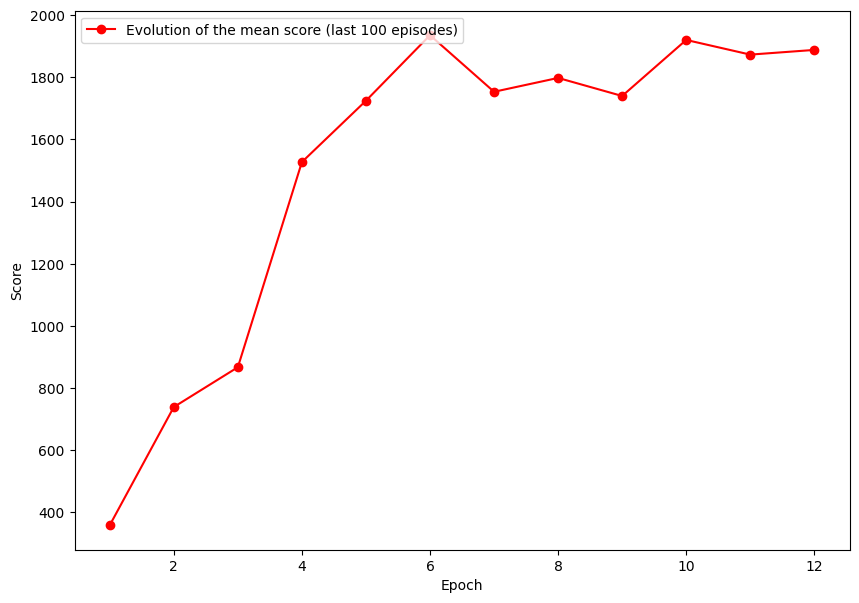

In [20]:
# Plot the mean score (last 100 episodes)

plt.figure(figsize=(10, 7))
plt.plot(epochs, mean_score_epoch, color='red', marker='o')
plt.xlabel('Epoch')
plt.ylabel('Score')
plt.legend(['Evolution of the mean score (last 100 episodes)'], loc='upper left')
plt.show()

$ \underline{Comments:} $ *(Update with your results.)* A random agent scores around 200–300 points per game in Ms. Pac-Man. We expect the mean score to increase quickly during the first epochs, while $\epsilon$ is decreasing, and then to keep growing more slowly as the agent learns to clear more pellets and to avoid the ghosts.

**Evolution of the best score**

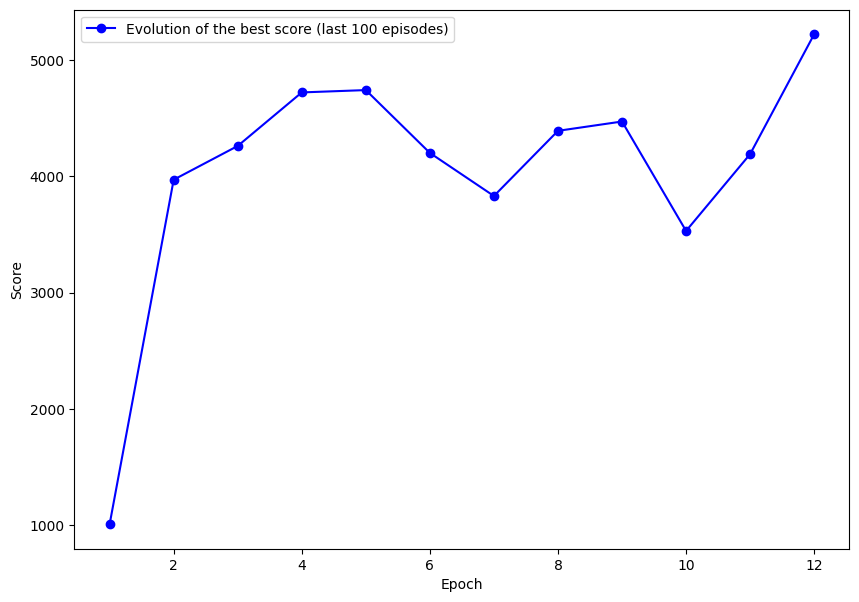

In [21]:
# Plot the max score (last 100 episodes)

plt.figure(figsize=(10, 7))
plt.plot(epochs, max_score_epoch, color='blue', marker='o')
plt.xlabel('Epoch')
plt.ylabel('Score')
plt.legend(['Evolution of the best score (last 100 episodes)'], loc='upper left')
plt.show()

$ \underline{Comments:} $ *(Update with your results.)* The best score is much noisier than the mean, because a single game where Pac-Man eats a power pellet and then catches several ghosts (200 + 400 + 800 + 1,600 points) can double the score of a normal game.

**Evolution of the loss**

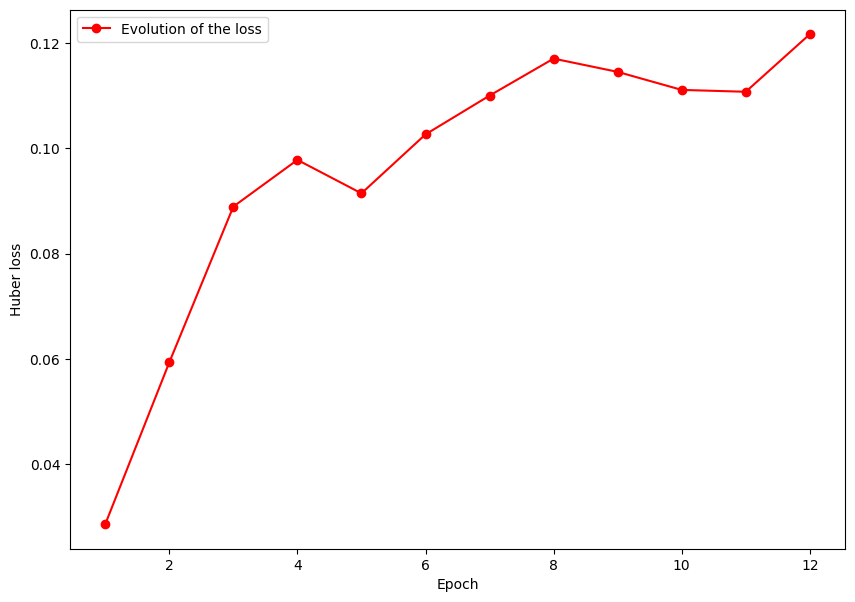

In [22]:
# Plot the mean loss of each epoch

plt.figure(figsize=(10, 7))
plt.plot(epochs, loss_epoch, color='red', marker='o')
plt.xlabel('Epoch')
plt.ylabel('Huber loss')
plt.legend(['Evolution of the loss'], loc='upper left')
plt.show()

$ \underline{Comments:} $ *(Update with your results.)* In reinforcement learning the loss does **not** need to go down monotonically like in supervised learning: the targets are computed with $Q_{target}$, which changes every 10,000 steps, and the data distribution changes as the policy improves. What matters is that the loss stays bounded (small values) and does not diverge, while the score keeps going up.

## **Activity 8:**

Now we will compare our trained agent against an agent that plays **completely at random**, over 10 full games each. For the trained agent we keep a small $\epsilon = 0.05$ so it does not get stuck repeating the same move against a wall.

Random agent:  mean 261.0  |  max 360
Dueling DQN:   mean 2090.0  |  max 2940


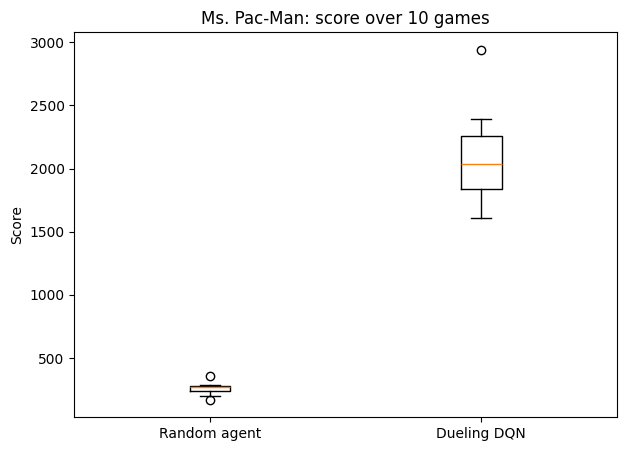

In [23]:
def evaluate(policy, n_episodes=10):
    eval_env = make_env()
    scores = []
    for ep in range(n_episodes):
        obs, info = eval_env.reset(seed=1000 + ep)
        done, score = False, 0
        while not done:
            obs, reward, terminated, truncated, info = eval_env.step(policy(obs))
            score += reward
            done = terminated or truncated
        scores.append(score)
    eval_env.close()
    return np.array(scores)

Q.eval()
random_scores  = evaluate(lambda s: np.random.randint(num_actions))
trained_scores = evaluate(lambda s: select_action(s, epsilon=0.05))

print(f'Random agent:  mean {random_scores.mean():.1f}  |  max {random_scores.max():.0f}')
print(f'Dueling DQN:   mean {trained_scores.mean():.1f}  |  max {trained_scores.max():.0f}')

plt.figure(figsize=(7, 5))
plt.boxplot([random_scores, trained_scores])
plt.xticks([1, 2], ['Random agent', 'Dueling DQN'])
plt.ylabel('Score')
plt.title('Ms. Pac-Man: score over 10 games')
plt.show()

$ \underline{Comments:} $ *(Update with your results.)* The difference between both boxes shows how much the agent actually learned beyond pure chance.

# Testing

Now we will test our model to show how our network learned, through the images of a full game.

In [24]:
frames = []

test_env = make_env(render_mode='rgb_array')
obs, info = test_env.reset(seed=seed)
frames.append(test_env.render())

done = False
while not done and len(frames) < 3_000:
    action = select_action(obs, epsilon=0.05)
    obs, reward, terminated, truncated, info = test_env.step(action)
    frames.append(test_env.render())
    done = terminated or truncated

test_env.close()
print('Number of frames:', len(frames))

Number of frames: 752


In [25]:
import matplotlib.animation
from IPython.display import HTML

frames_show = frames[::2]   # We show one of every two frames so the animation is lighter

fig = plt.figure(figsize=(frames_show[0].shape[1] / 40.0, frames_show[0].shape[0] / 40.0), dpi=72)
patch = plt.imshow(frames_show[0])
plt.axis('off')
animate = lambda i: patch.set_data(frames_show[i])
ani = matplotlib.animation.FuncAnimation(fig, animate, frames=len(frames_show), interval=50)
plt.close(fig)
HTML(ani.to_jshtml())

In [26]:
# We will save this animation as a .gif

os.makedirs(my_path, exist_ok=True)
path_gif = os.path.join(my_path, 'pacman.gif')
writergif = matplotlib.animation.PillowWriter(fps=20)
ani.save(path_gif, writer=writergif)
print('Saved in', path_gif)

Saved in drive/MyDrive/DeepLearningUC/PacMan/Checkpoints/pacman.gif


$ \underline{Comments:} $ *(Update with your results.)* Things to look for in the animation: does Pac-Man run away from the ghosts when they get close? Does it go for the ghosts after eating a power pellet? Does it clear whole corridors, or does it leave isolated pellets behind? The action policy should look varied and reactive, not a fixed pattern like "always go left".

## **References:**

Here are all the web pages and material I used as a base for this project.

[1] Wang, Z. et al. (2016). *Dueling Network Architectures for Deep Reinforcement Learning.* https://arxiv.org/abs/1511.06581

[2] van Hasselt, H., Guez, A. & Silver, D. (2016). *Deep Reinforcement Learning with Double Q-learning.* https://arxiv.org/abs/1509.06461

[3] Mnih, V. et al. (2015). *Human-level control through deep reinforcement learning.* Nature 518, 529–533.

[4] Gymnasium – Atari preprocessing wrappers: https://gymnasium.farama.org/

[5] Arcade Learning Environment – Ms. Pac-Man: https://ale.farama.org/environments/ms_pacman/

[6] https://github.com/gouxiangchen/dueling-DQN-pytorch